import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Load and Validate Image (Handles Colab upload or creates a safe fallback pattern if needed)
print("--- Loading and Validating Grayscale Image ---")
# If running in Colab, you can upload your image or use a built-in OpenCV sample
try:
  # Try loading a standard test image and converting to grayscale
  original_rgb = cv2.cvtColor(
      cv2.imread(cv2.samples.findFile("lena.jpg")), cv2.COLOR_BGR2RGB
  )
  gray_img = cv2.cvtColor(original_rgb, cv2.COLOR_RGB2GRAY)
except:
  # Fallback synthetic pattern (at least 300x300 pixels) if file is missing
  x = np.linspace(0, 255, 400)
  y = np.linspace(0, 255, 400)
  xx, yy = np.meshgrid(x, y)
  gray_img = np.uint8(np.abs(np.sin(xx / 30) * 127 + np.cos(yy / 30) * 128))

# Ensure dimensions are at least 300x300
if gray_img.shape[0] < 300 or gray_img.shape[1] < 300:
  gray_img = cv2.resize(gray_img, (400, 400))

# Display properties
print(f"Image Shape: {gray_img.shape}")
print(f"Data Type (dtype): {gray_img.dtype}")
print(f"Minimum Intensity: {np.min(gray_img)}")
print(f"Maximum Intensity: {np.max(gray_img)}")

# Display Original
plt.figure(figsize=(5, 5))
plt.imshow(gray_img, cmap='gray', vmin=0, vmax=255)
plt.title('Original Grayscale Image')
plt.axis('off')
plt.show()

Image successfully load ho gayi hai! Shape: (762, 1200)


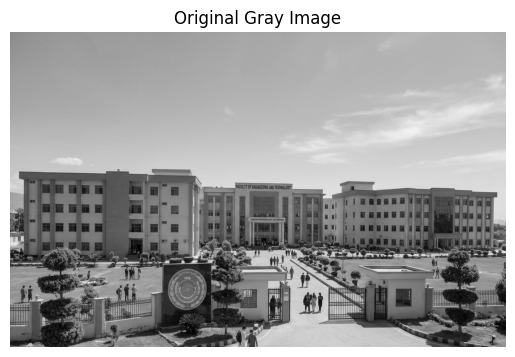

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the uploaded image in Grayscale
img_path = '/content/Gemini_Generated_Image_gc7373gc7373gc73.jpg'
gray_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

if gray_img is None:
    print("Error: Image load nahi ho saki. Please check path aur file name.")
else:
    print(f"Image successfully load ho gayi hai! Shape: {gray_img.shape}")
    # Display original image
    plt.imshow(gray_img, cmap='gray')
    plt.title('Original Gray Image')
    plt.axis('off')
    plt.show()

--- Task 1: Brightness Adjustment (+40 and -40) ---
Do NumPy and Nested Loop implementations match perfectly? True


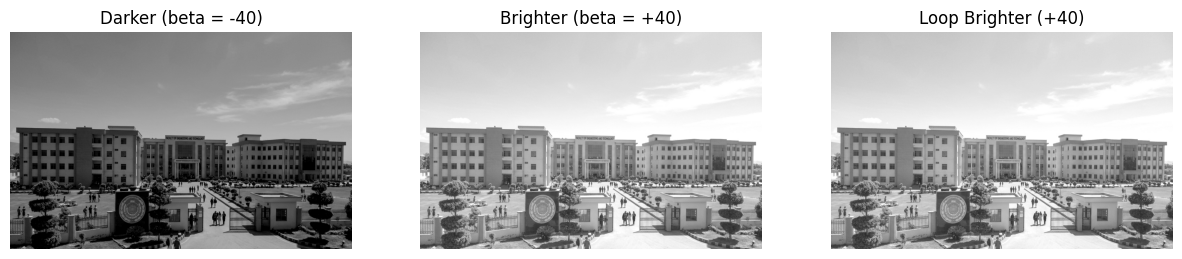

In [4]:
print('--- Task 1: Brightness Adjustment (+40 and -40) ---')

# Vectorized NumPy approach
img_f32 = gray_img.astype(np.float32)
bright_img = np.clip(img_f32 + 40, 0, 255).astype(np.uint8)
dark_img = np.clip(img_f32 - 40, 0, 255).astype(np.uint8)

# Nested loop approach for +40 verification
h, w = gray_img.shape
loop_bright = np.zeros((h, w), dtype=np.uint8)
for i in range(h):
  for j in range(w):
    val = int(gray_img[i, j]) + 40
    loop_bright[i, j] = 255 if val > 255 else (0 if val < 0 else val)

# Verify equality
match = np.array_equal(bright_img, loop_bright)
print(f'Do NumPy and Nested Loop implementations match perfectly? {match}')

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(dark_img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Darker (beta = -40)')
axes[1].imshow(bright_img, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Brighter (beta = +40)')
axes[2].imshow(loop_bright, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Loop Brighter (+40)')
for ax in axes:
  ax.axis('off')
plt.show()

--- Task 2: Linear Contrast from Zero (alpha=1.5, beta=0) ---


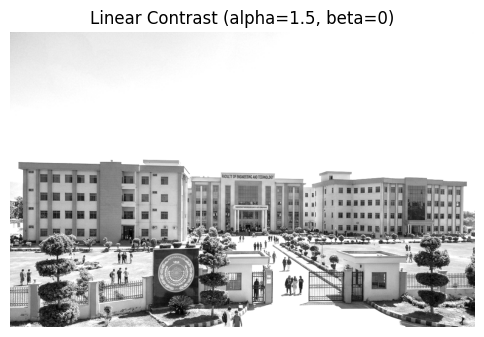

In [5]:
print('--- Task 2: Linear Contrast from Zero (alpha=1.5, beta=0) ---')

alpha = 1.5
beta = 0
linear_contrast = np.clip(alpha * img_f32 + beta, 0, 255).astype(np.uint8)

plt.figure(figsize=(6, 6))
plt.imshow(linear_contrast, cmap='gray', vmin=0, vmax=255)
plt.title('Linear Contrast (alpha=1.5, beta=0)')
plt.axis('off')
plt.show()

--- Task 3: Contrast Centered at 128 (alpha = 1.5 and 0.5) ---


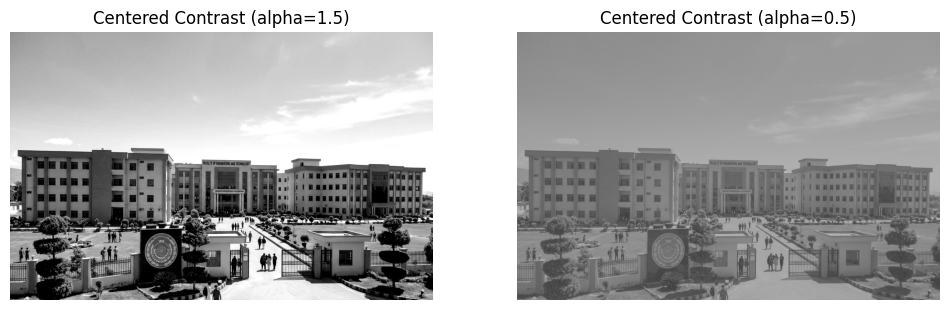

In [6]:
print('--- Task 3: Contrast Centered at 128 (alpha = 1.5 and 0.5) ---')

alpha_1 = 1.5
alpha_2 = 0.5
contrast_128_high = np.clip(
    (img_f32 - 128) * alpha_1 + 128, 0, 255
).astype(np.uint8)
contrast_128_low = np.clip((img_f32 - 128) * alpha_2 + 128, 0, 255).astype(
    np.uint8
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(contrast_128_high, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Centered Contrast (alpha=1.5)')
axes[1].imshow(contrast_128_low, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Centered Contrast (alpha=0.5)')
for ax in axes:
  ax.axis('off')
plt.show()

--- Task 4: Image Negative ---


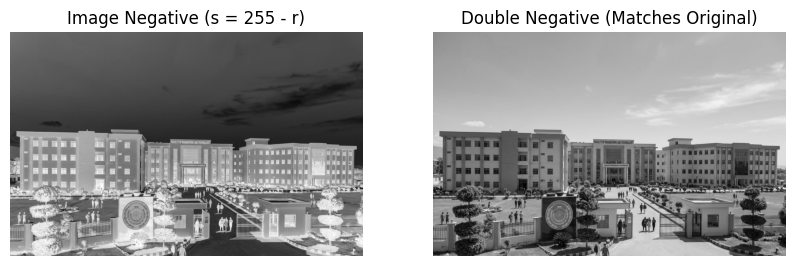

In [7]:
print('--- Task 4: Image Negative ---')

neg_img = 255 - gray_img
double_neg = 255 - neg_img  # Should match original exactly

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(neg_img, cmap='gray', vmin=0, vmax=255)
plt.title('Image Negative (s = 255 - r)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(double_neg, cmap='gray', vmin=0, vmax=255)
plt.title('Double Negative (Matches Original)')
plt.axis('off')
plt.show()

--- Task 5: Gamma Correction (gamma = 0.5 and 2.0) ---


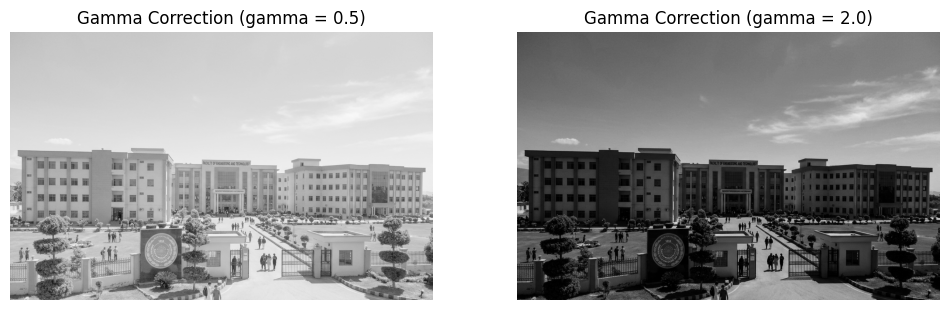

In [8]:
print('--- Task 5: Gamma Correction (gamma = 0.5 and 2.0) ---')

norm_img = img_f32 / 255.0
gamma_low = np.clip(255 * np.power(norm_img, 0.5), 0, 255).astype(np.uint8)
gamma_high = np.clip(255 * np.power(norm_img, 2.0), 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(gamma_low, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Gamma Correction (gamma = 0.5)')
axes[1].imshow(gamma_high, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Gamma Correction (gamma = 2.0)')
for ax in axes:
  ax.axis('off')
plt.show()

--- Task 6: Grayscale Histogram ---


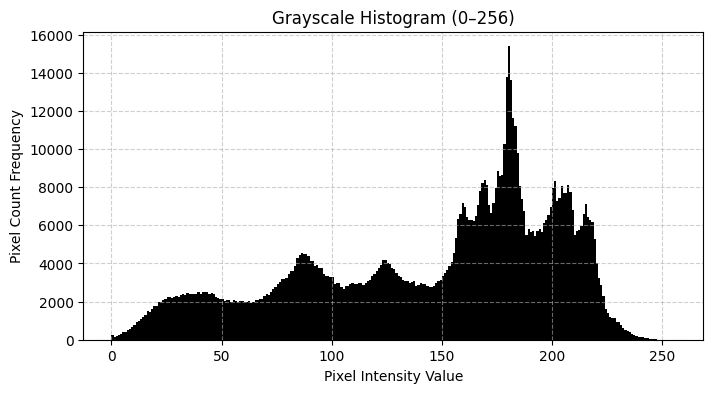

In [9]:
print('--- Task 6: Grayscale Histogram ---')

plt.figure(figsize=(8, 4))
plt.hist(gray_img.ravel(), bins=256, range=[0, 256], color='black')
plt.title('Grayscale Histogram (0–256)')
plt.xlabel('Pixel Intensity Value')
plt.ylabel('Pixel Count Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

--- Task 7: Global Histogram Equalization ---


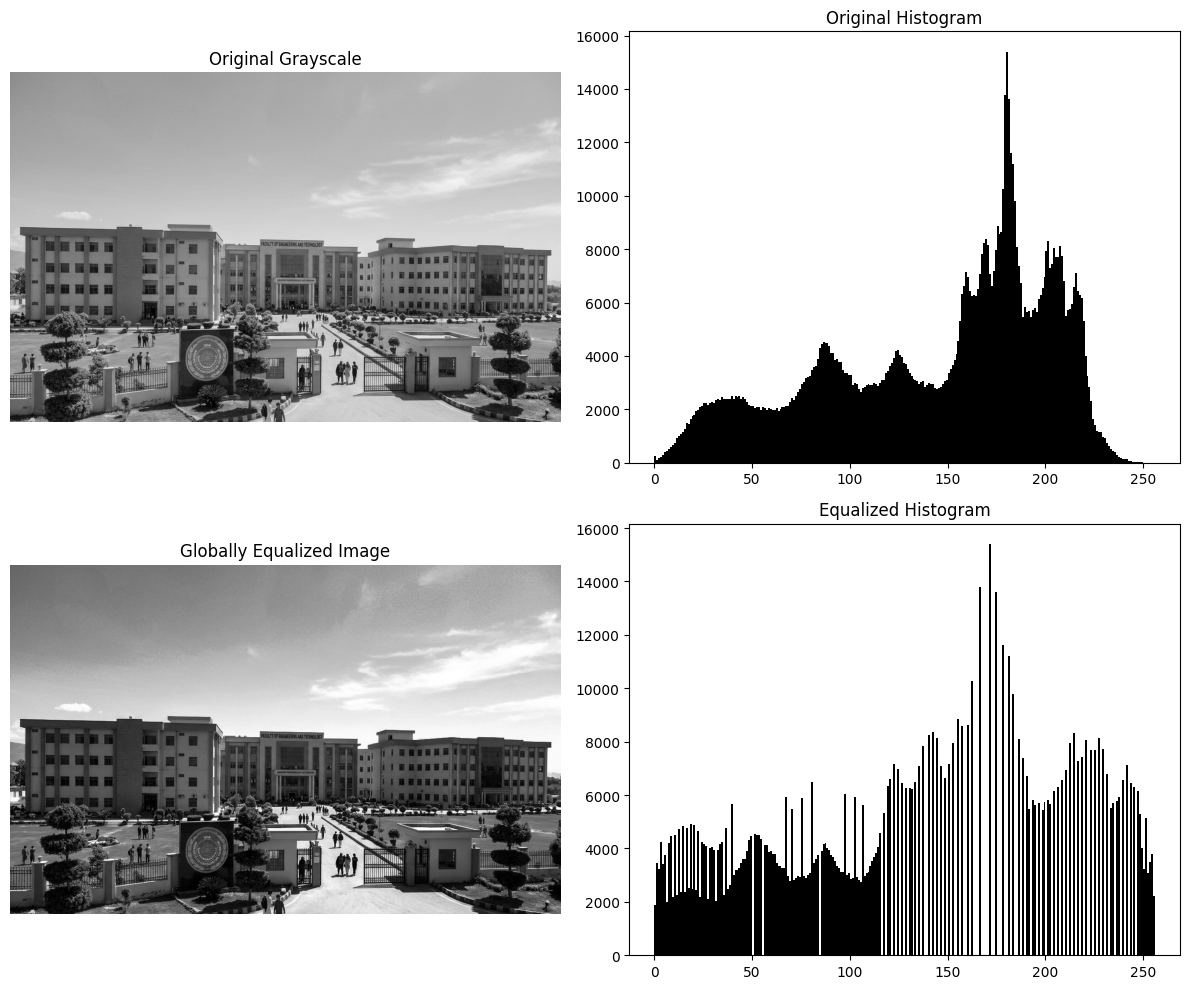

In [10]:
print('--- Task 7: Global Histogram Equalization ---')

eq_img = cv2.equalizeHist(gray_img)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].imshow(gray_img, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title('Original Grayscale')
axes[0, 1].hist(gray_img.ravel(), bins=256, range=[0, 256], color='black')
axes[0, 1].set_title('Original Histogram')

axes[1, 0].imshow(eq_img, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title('Globally Equalized Image')
axes[1, 1].hist(eq_img.ravel(), bins=256, range=[0, 256], color='black')
axes[1, 1].set_title('Equalized Histogram')

for row in axes:
  for ax in row:
    if not ax.get_title().endswith('Histogram'):
      ax.axis('off')
plt.tight_layout()
plt.show()

--- Task 8: CLAHE ---


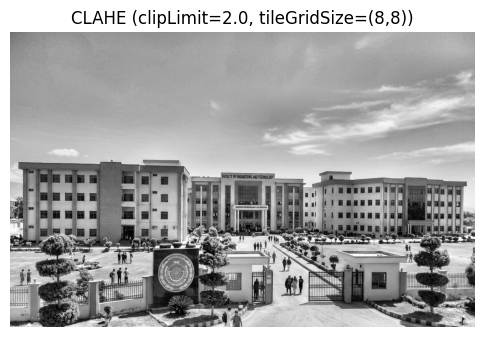

In [11]:
print('--- Task 8: CLAHE ---')

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img = clahe.apply(gray_img)

plt.figure(figsize=(6, 6))
plt.imshow(clahe_img, cmap='gray', vmin=0, vmax=255)
plt.title('CLAHE (clipLimit=2.0, tileGridSize=(8,8))')
plt.axis('off')
plt.show()

--- Task 9: Fixed Binary Thresholding (T = 127) ---
Unique pixel values in fixed threshold mask: [  0 255]


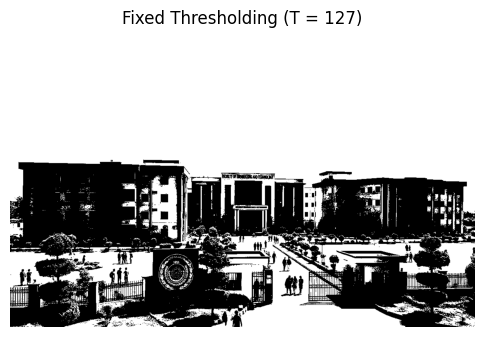

In [12]:
print('--- Task 9: Fixed Binary Thresholding (T = 127) ---')

T_fixed = 127
_, thresh_fixed = cv2.threshold(gray_img, T_fixed, 255, cv2.THRESH_BINARY)
print(f'Unique pixel values in fixed threshold mask: {np.unique(thresh_fixed)}')

plt.figure(figsize=(6, 6))
plt.imshow(thresh_fixed, cmap='gray', vmin=0, vmax=255)
plt.title(f'Fixed Thresholding (T = {T_fixed})')
plt.axis('off')
plt.show()

--- Task 10: Otsu Thresholding ---
Optimal Threshold Value determined by Otsu: 129.0


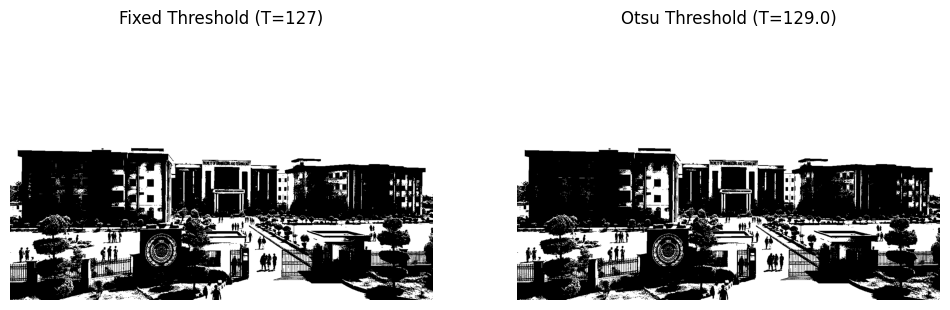

In [13]:
print('--- Task 10: Otsu Thresholding ---')

otsu_thresh_val, thresh_otsu = cv2.threshold(
    gray_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
print(f'Optimal Threshold Value determined by Otsu: {otsu_thresh_val}')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(thresh_fixed, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f'Fixed Threshold (T={T_fixed})')
axes[1].imshow(thresh_otsu, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f'Otsu Threshold (T={otsu_thresh_val})')
for ax in axes:
  ax.axis('off')
plt.show()

--- Task 11: Adaptive Gaussian Thresholding ---


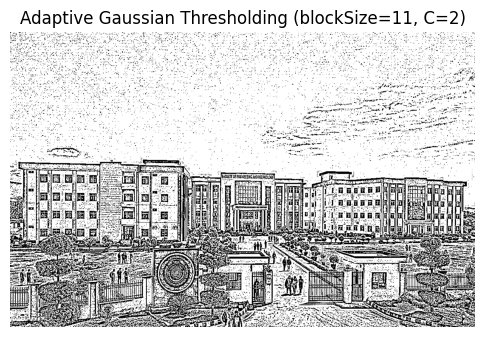

In [14]:
print('--- Task 11: Adaptive Gaussian Thresholding ---')

adaptive_img = cv2.adaptiveThreshold(
    gray_img,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    blockSize=11,
    C=2,
)

plt.figure(figsize=(6, 6))
plt.imshow(adaptive_img, cmap='gray', vmin=0, vmax=255)
plt.title(
    'Adaptive Gaussian Thresholding (blockSize=11, C=2)'
)
plt.axis('off')
plt.show()